<a name='link2'>**<center><font size=6>Job Change Dataset</font></center>**</a>

## Import necessary libraries..

In [ ]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

## Loading the dataset..

In [ ]:
# 1. mounted the drive into colab notebook
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# 2. Load the dataset into pandas dataframe
df = pd.read_csv("/content/drive/MyDrive/Datasets [ML Pipeline]/jobs_data.csv")

## Data Overview..

In [ ]:
# 1. View the first 5 rows of the dataset
df.head()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.0


In [ ]:
# 2. View the last 5 rows of the dataset
df.tail()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
19153,7386,city_173,0.878,Male,No relevent experience,no_enrollment,Graduate,Humanities,14,NaN,NaN,1,42,1.0
19154,31398,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,14,NaN,NaN,4,52,1.0
19155,24576,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,50-99,Pvt Ltd,4,44,0.0
19156,5756,city_65,0.802,Male,Has relevent experience,no_enrollment,High School,NaN,<1,500-999,Pvt Ltd,2,97,0.0
19157,23834,city_67,0.855,NaN,No relevent experience,no_enrollment,Primary School,NaN,2,NaN,NaN,1,127,0.0


- The dataset contains information about different applicants.

In [ ]:
# 3. Understand the shape of the dataset
df.shape

(19158, 14)

- The dataset has 19,158 rows and 14 columns.

In [ ]:
# 4. Check the data types of the columns for the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   enrollee_id             19158 non-null  int64  
 1   city                    19158 non-null  object 
 2   city_development_index  19158 non-null  float64
 3   gender                  14650 non-null  object 
 4   relevent_experience     19158 non-null  object 
 5   enrolled_university     18772 non-null  object 
 6   education_level         18698 non-null  object 
 7   major_discipline        16345 non-null  object 
 8   experience              19093 non-null  object 
 9   company_size            13220 non-null  object 
 10  company_type            13018 non-null  object 
 11  last_new_job            18735 non-null  object 
 12  training_hours          19158 non-null  int64  
 13  target                  19158 non-null  float64
dtypes: float64(2), int64(2), object(10)
me

- There are 14 columns and 19,158 rows in the dataset.
- We have only four continuous varoables - enrollee_id, city_development_index, training_hours, and target.
- All other variables are categorical.
- The dataset contain missing values in 8 out of 14 columns. The columns company_type (missing about 6,140 values), company_size, gender, and major_discipline have the highest amount of missing data.
- **ID Column:** The enrollee_id is just a unique identification number for each person. You should drop this column when creating your features (X).

In [ ]:
# 5. Checking for duplicate values
df.duplicated().sum()

np.int64(0)

- There are no duplicate values in the dataset.

In [ ]:
# 6. Checking for missing values
df.isnull().sum()

,0
enrollee_id,0
city,0
city_development_index,0
gender,4508
relevent_experience,0
enrolled_university,386
education_level,460
major_discipline,2813
experience,65
company_size,5938


- **Perfect Columns (0 Missing):** 6 columns (like target, city, and training_hours) have no missing values. They are clean and ready to use.

- **High Missing Data:** company_type, company_size, and gender have thousands of missing values (4,500 to 6,100+).

- **Low Missing Data:** Columns like experience (only 65 missing) and education_level (460 missing) have very few blanks.

In [ ]:
# 7. Statistical Summary
df.describe().T

,count,mean,std,min,25%,50%,75%,max
enrollee_id,19158.0,16875.358179,9616.292592,1.000,8554.25,16982.500,25169.75,33380.000
city_development_index,19158.0,0.828848,0.123362,0.448,0.74,0.903,0.92,0.949
training_hours,19158.0,65.366896,60.058462,1.000,23.00,47.000,88.00,336.000
target,19158.0,0.249348,0.432647,0.000,0.00,0.000,0.00,1.000


- **Target Column (Imbalanced Data):** The mean of the target is 0.249. Since this column only contains 0s and 1s, this means exactly 24.9% (~25%) of the people belong to class 1, while the remaining 75% belong to class 0.

- **Training Hours (Right Skewed)**: Most people complete around 47 hours of training (the 50% Median mark). However, a few extreme outliers train for up to 336 hours (Max), which artificially pulls the average (Mean) up to 65.3 hours.

- **City Development Index (Left Skewed):** Most candidates come from highly developed cities (the Median is a high 0.903). However, a few candidates from less developed cities (Min is 0.448) pull the average down slightly to 0.828.

- **Enrollee ID (Useless Stats):** The mean and standard deviation of an ID column mean absolutely nothing. As observed before, this column should be dropped before giving the data to your machine learning model.

In [ ]:
# 8. Observation of Categorical varibales
# making list of all categorial variables
cat_col = [
    'city',
    'gender',
    'relevent_experience',
    'enrolled_university',
    'education_level',
    'major_discipline',
    'experience',
    'company_size',
    'company_type',
    'last_new_job'
]

# Printing number of count of each unique value in each column
for col in cat_col:
  print(df[col].value_counts())
  print("-"*40)

city
city_103    4355
city_21     2702
city_16     1533
city_114    1336
city_160     845
            ... 
city_111       3
city_129       3
city_121       3
city_140       1
city_171       1
Name: count, Length: 123, dtype: int64
----------------------------------------
gender
Male      13221
Female     1238
Other       191
Name: count, dtype: int64
----------------------------------------
relevent_experience
Has relevent experience    13792
No relevent experience      5366
Name: count, dtype: int64
----------------------------------------
enrolled_university
no_enrollment       13817
Full time course     3757
Part time course     1198
Name: count, dtype: int64
----------------------------------------
education_level
Graduate          11598
Masters            4361
High School        2017
Phd                 414
Primary School      308
Name: count, dtype: int64
----------------------------------------
major_discipline
STEM               14492
Humanities           669
Other             

- **Demographics:** The dataset is heavily dominated by Males (over 90% of those who provided their gender). The vast majority of people also studied STEM (Science, Technology, Engineering, Math) as their major discipline.

- **Education & Enrollment:** Most candidates are highly educated, with the majority being Graduates or holding Masters degrees. Additionally, most of them are not currently enrolled in any university, meaning they are likely full-time working professionals.

- **Work Experience:** Most people already have relevant experience. Interestingly, the most common experience level is >20 years, showing a strong presence of very senior professionals.

- **Company Profile:** When it comes to workplaces, the majority work for Private Limited (Pvt Ltd) companies. The company sizes are mixed, but companies with 50-500 employees and massive corporations with 10,000+ employees are the most common.

- **Job History:** Most people have exactly 1 (likely meaning 1 year since their last job or 1 previous job). However, a large group has never changed jobs, which might indicate people who are still at their very first company.

- **Location (Cities):** Although the data is spread across 123 different cities, city_103 is by far the most common location, holding significantly more people than any other city.

## <a name='link2'>Exploratory Data Analysis (EDA)</a>

### Univariate Analysis

In [ ]:
def histogram_boxplot(data, feature, figsize=(12, 7), kde=True, bins=None):
    """
    Boxplot and histogram combined (Attractive Version)
    """
    # 1. Set a clean and professional background theme
    sns.set_theme(style="whitegrid", palette="pastel")

    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,
        sharex=True,
        gridspec_kw={"height_ratios": (0.2, 0.8)}, # Boxplot ko thoda patla aur hist ko bada kiya
        figsize=figsize,
    )

    # 2. Attractive Boxplot with Custom Colors & Outliers
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True,
        color="#FF9F36", # Vibrant Orange for the box
        flierprops={"marker": "o", "markerfacecolor": "#E74C3C", "markersize": 6, "alpha": 0.6}, # Highlight outliers in red
        meanprops={"marker": "^", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 8} # Pop-out mean triangle
    )
    ax_box2.set(xlabel="") # Remove overlapping x-label
    ax_box2.set_title(f"Distribution Analysis of {feature}", fontsize=16, fontweight='bold', color='#2C3E50', pad=15)

    # 3. Stylish Histogram with Edge Colors
    hist_kwargs = {
        "data": data,
        "x": feature,
        "kde": kde,
        "ax": ax_hist2,
        "color": "#3498DB", # Nice blue fill
        "edgecolor": "black", # Black borders for bins
        "linewidth": 1,
        "alpha": 0.7 # Slight transparency
    }

    if bins:
        sns.histplot(**hist_kwargs, bins=bins)
    else:
        sns.histplot(**hist_kwargs)

    # 4. Mean and Median Lines with Legends & Values
    mean_val = data[feature].mean()
    median_val = data[feature].median()

    ax_hist2.axvline(mean_val, color="#E74C3C", linestyle="--", linewidth=2.5, label=f"Mean: {mean_val:.2f}")
    ax_hist2.axvline(median_val, color="#2ECC71", linestyle="-", linewidth=2.5, label=f"Median: {median_val:.2f}")

    # 5. Formatting Labels, Legend, and Spines
    ax_hist2.legend(fontsize=11, frameon=True, shadow=True, loc="upper right")
    ax_hist2.set_xlabel(feature, fontsize=13, fontweight='bold', color='#34495E')
    ax_hist2.set_ylabel("Frequency", fontsize=13, fontweight='bold', color='#34495E')

    sns.despine(ax=ax_hist2) # Remove top and right borders
    sns.despine(ax=ax_box2, left=True) # Clean up boxplot borders

    plt.tight_layout()
    plt.show()

In [ ]:
def labeled_barplot(data, feature, perc=False, n=None, palette="viridis"):
    """
    Barplot with percentage or count at the top

    data: dataframe
    feature: dataframe column
    perc: whether to display percentages instead of count (default is False)
    n: displays the top n category levels (default is None, i.e., display all levels)
    palette: color theme for the bars
    """
    # Total count calculation (ignoring missing values for accurate percentage)
    total = len(data[feature].dropna())
    count = data[feature].nunique()

    if n is None:
        plt.figure(figsize=(count + 3, 6))
    else:
        plt.figure(figsize=(n + 3, 6))

    # 1. Make the background style clean and modern
    sns.set_theme(style="whitegrid")

    # 2. Drawing a bar plot with vibrant colors and borders
    ax = sns.countplot(
        data=data,
        x=feature,
        palette=palette,
        order=data[feature].value_counts().index[:n],
        edgecolor="black",
        linewidth=1.5
    )

    # 3. formatting of Text aur Labels(Bold aur clear)
    plt.xticks(rotation=45, fontsize=12, fontweight='bold', ha='right')
    plt.yticks(fontsize=12)
    plt.title(f"Distribution of {feature.capitalize()}", fontsize=16, fontweight='bold', pad=15)
    plt.xlabel(feature.capitalize(), fontsize=14, fontweight='bold')
    plt.ylabel("Count", fontsize=14, fontweight='bold')

    for p in ax.patches:
        height = p.get_height()
        # If height is NaN then skip this
        if pd.isna(height) or height == 0:
            continue

        if perc == True:
            # BUG FIX: Your old code had '100p'; it needs to be changed to '100 * height'.
            label = "{:.1f}%".format(100 * height / total)
        else:
            label = int(height)

        x = p.get_x() + p.get_width() / 2
        y = height

        # 4. Making the annotations bold and shifting them slightly upwards
        ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=12,
            fontweight='bold',
            color="black",
            xytext=(0, 8),
            textcoords="offset points",
        )

    # 5. Removing the top and right borders of the box for a clean look
    sns.despine(left=True, bottom=True)

    plt.tight_layout()
    plt.show()

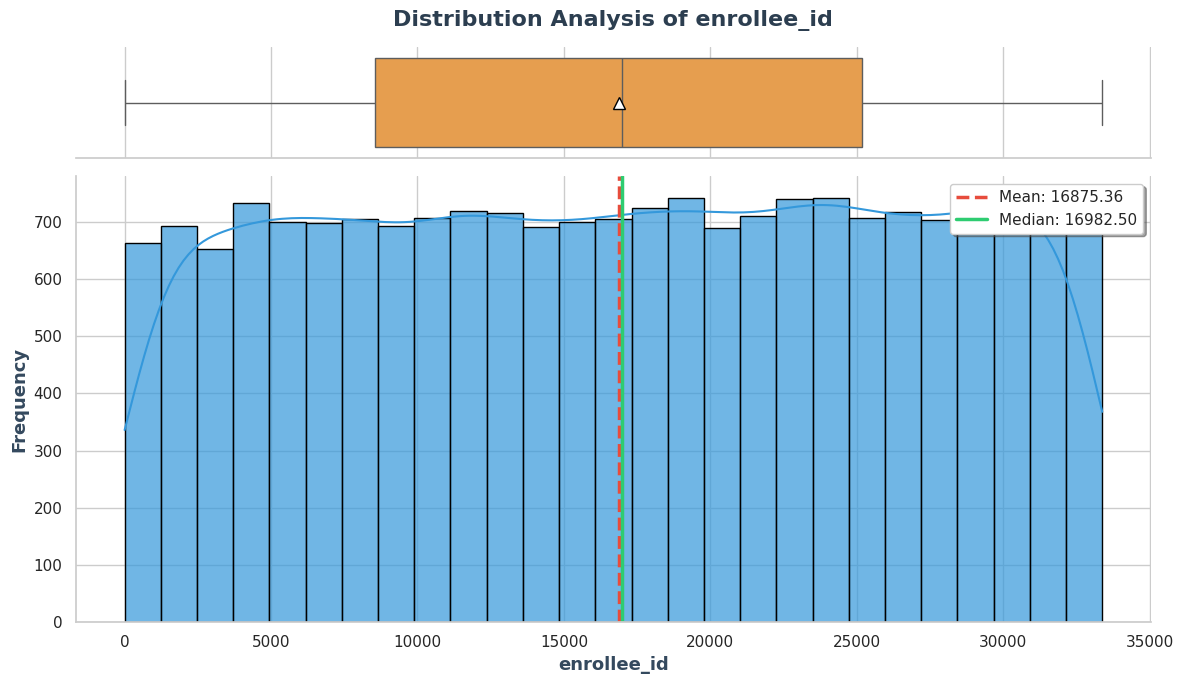

In [ ]:
# 1. Observation of "Enrollee_id"
histogram_boxplot(df, "enrollee_id")

- **Uniform Spread:** The histogram shows a completely flat, uniform distribution. This means the ID numbers are spread evenly across the entire range without any peaks or clusters.   
- **Perfectly Centered:** The Mean (16875.36) and Median (16982.50) are almost exactly the same and sit right in the middle of the graph.   No Outliers: The boxplot at the top is symmetric and shows that there are zero outliers.  
- **Final Takeaway:** This flat shape confirms that enrollee_id is just a sequential or random identification number. Because it has no real mathematical meaning or pattern, you should drop this column before training your machine learning model.

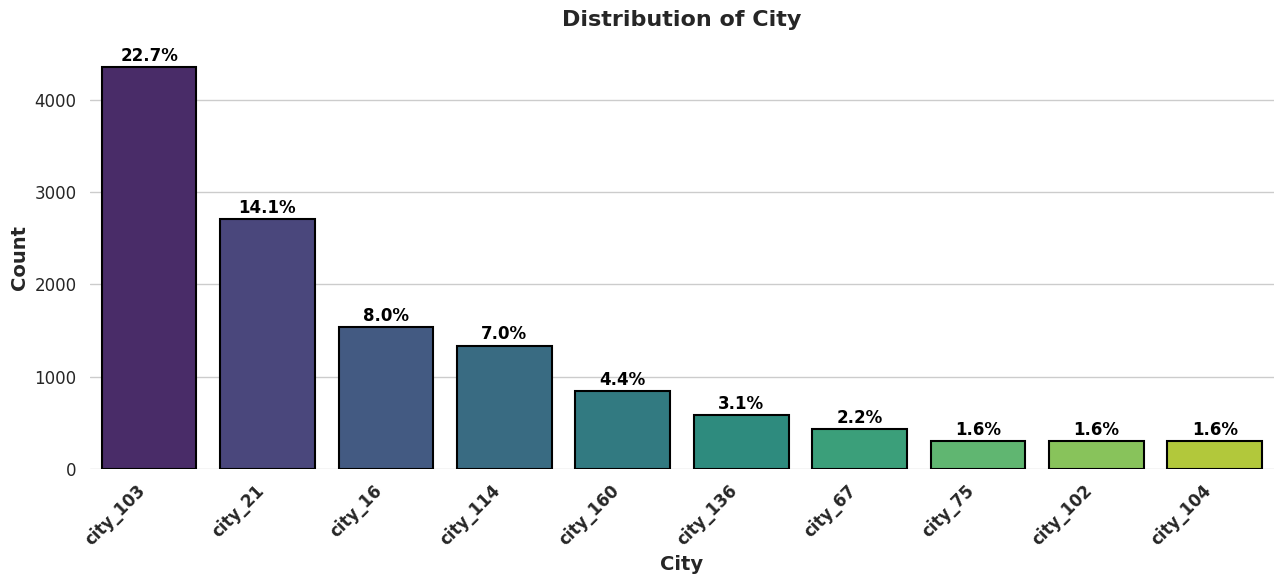

In [ ]:
# 2. Observation of 'City'
# Top 10 cities observations because cities is soo more
labeled_barplot(df, feature="city", perc=True, n=10)

- **Top Contributor:** The most common city in the dataset is city_103, representing a major portion at 22.7%.   
- **Second Largest:** The city city_21 follows as the second highest, accounting for 14.1% of the data.   
- **Heavy Concentration:** Just the top two cities (city_103 and city_21) combined make up more than a third (36.8%) of the total distribution.   
- **Sharp Decline:** There is a steep drop-off after the second city, with the remaining top cities (city_16 down to city_104) contributing much smaller amounts, ranging from 8.0% down to just 1.6% each.

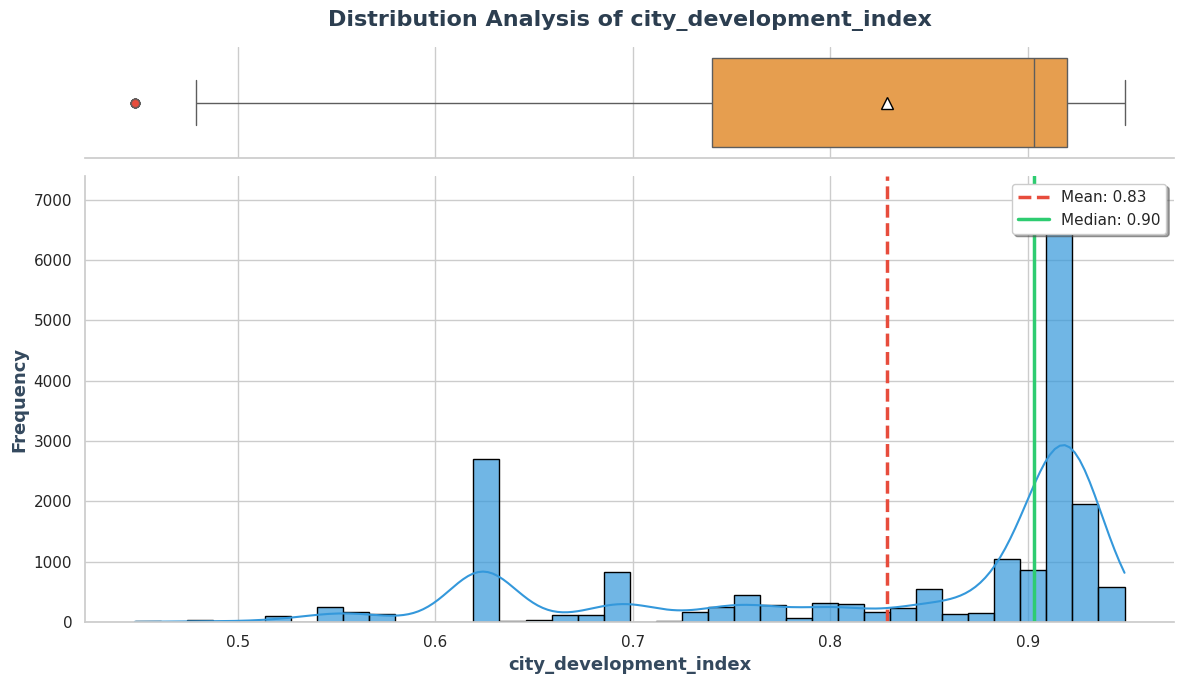

In [ ]:
# 3. Observation of 'City_development_index'
histogram_boxplot(df, 'city_development_index')

- **High Development Focus:** The data is heavily clustered on the right side, with a massive peak just above the 0.90 mark. This means the vast majority of candidates come from highly developed cities.   
- **Averages (Left-Skewed):** The Median is high at 0.90, but the Mean is lower at 0.83. This happens because a few low-scoring cities are pulling the average down, creating a "left-skewed" distribution (a long tail to the left).   
- **A Secondary Group:** There is another distinct, smaller peak around the 0.62 mark. This indicates a secondary group of candidates coming from cities with medium development.   
- **Outliers:** The boxplot at the top shows a long whisker stretching to the left, with a single outlier dot near 0.45. This confirms that while rare, there are a few cities in the dataset with very low development indices.

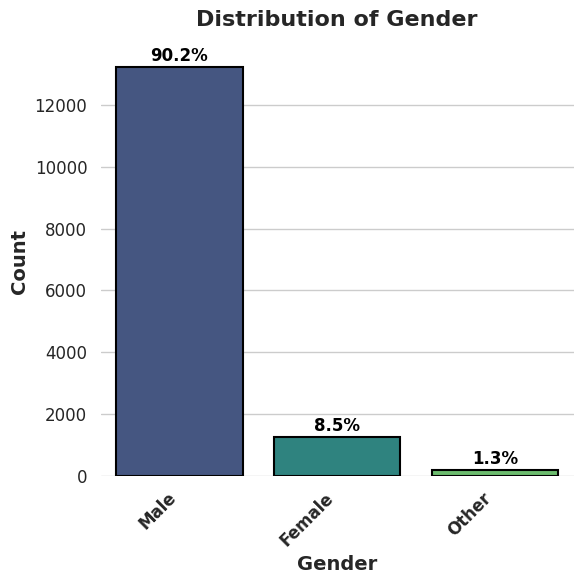

In [ ]:
# 4. Observation of 'Gender'
labeled_barplot(df, "gender", perc=True)

- **Male Dominated:** The vast majority of the people in this dataset are Male, making up an overwhelming 90.2% of the total.   
- **Small Female Minority:** Females represent a very small portion of the data at just 8.5%.   
- **Other Category:** The remaining 1.3% of the candidates fall into the "Other" gender category.   
- **Highly Imbalanced:** Overall, this shows that the dataset is highly imbalanced regarding gender, which might cause bias in a machine learning model.

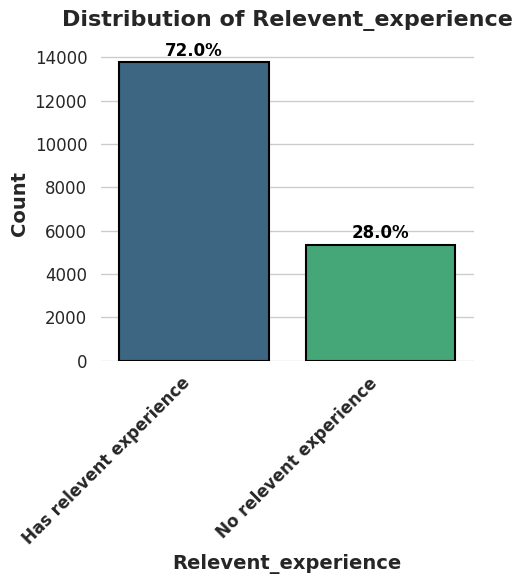

In [ ]:
# 5. Observation of 'Revelent_experience'
labeled_barplot(df, 'relevent_experience', perc=True)

- **Majority with Experience:** The clear majority of candidates in the dataset already possess relevant experience, making up 72.0% of the total.   
- **Minority without Experience:** The remaining 28.0% of the candidates fall into the category of having no relevant experience.   
- **Clear Imbalance:** Overall, there are roughly two and a half times more people with relevant experience than those without it.

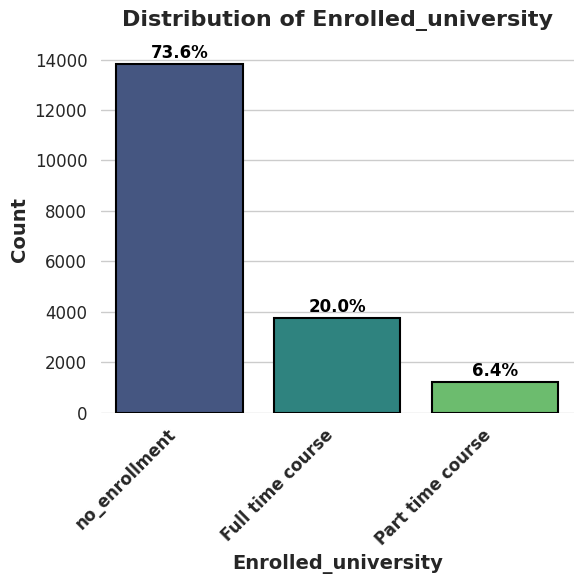

In [ ]:
# 6. Observation of 'Enrolled_university'
labeled_barplot(df, 'enrolled_university', perc=True)

- **Not Enrolled (Majority):** The vast majority of candidates are not currently enrolled in any university, accounting for 73.6% of the dataset.   
- **Full-Time Students:** Exactly 20.0% of the individuals are enrolled in a full-time university course.   
- **Part-Time Students:** The smallest group consists of candidates taking a part-time course, making up just 6.4% of the total.   
- **Key Takeaway:** Nearly three-quarters of the people are likely working professionals rather than active students.   

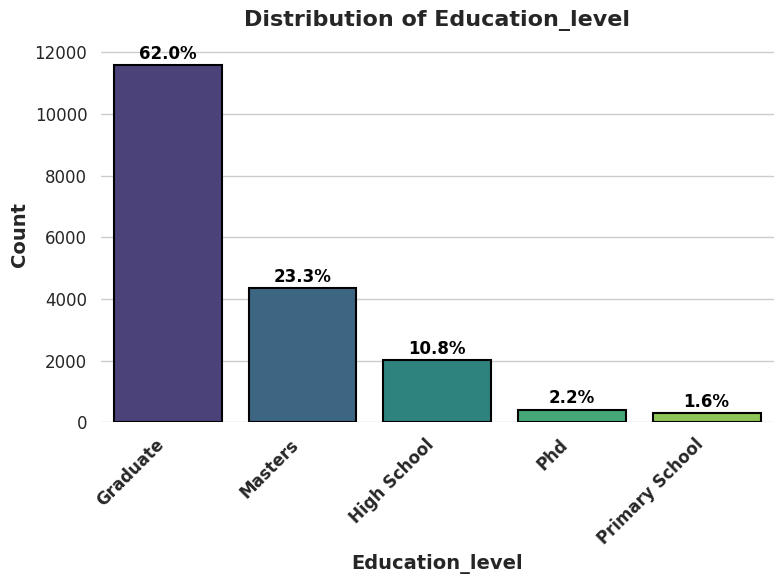

In [ ]:
# 7. Observation of 'Education_level'
labeled_barplot(df, 'education_level', perc=True)

- **Majority are Graduates:** The largest group in the dataset consists of Graduates, making up 62.0% of the total.   
- **Masters Degree:** The second most common education level is a Masters degree, representing 23.3% of the candidates.   
- **High School Level:** People with a High School education make up a smaller portion at 10.8%.   
- **Rare Categories:** Very few individuals hold a Phd (2.2%) or have only a Primary School education (1.6%).   
- **Key Takeaway:** Over 85% of the individuals are highly educated, holding either a Graduate or Masters degree.

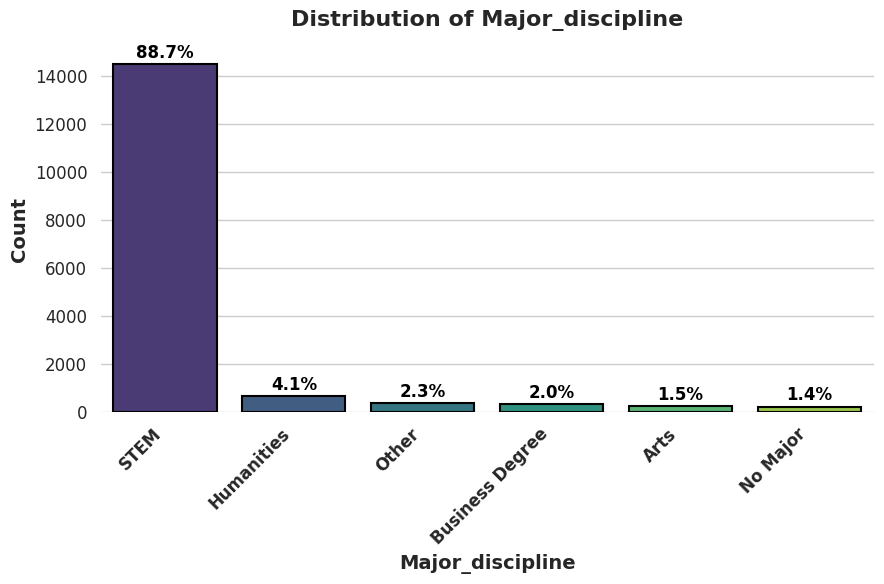

In [ ]:
# 8. Observation of 'Major_discipline'
labeled_barplot(df, 'major_discipline', perc=True)

- **STEM Dominated:** The overwhelming majority of individuals majored in a STEM (Science, Technology, Engineering, Mathematics) field, making up 88.7% of the dataset.   
- **Minority Disciplines:** All other disciplines represent a tiny fraction of the data. Humanities is the second most common major but accounts for only 4.1%.   - **Rare Majors:** Fields like Business Degrees (2.0%), Arts (1.5%), and having "No Major" (1.4%) are extremely rare among the candidates.   
- **Key Takeaway:** The dataset is heavily imbalanced, showing a massive preference or availability of candidates with technical and scientific educational backgrounds.

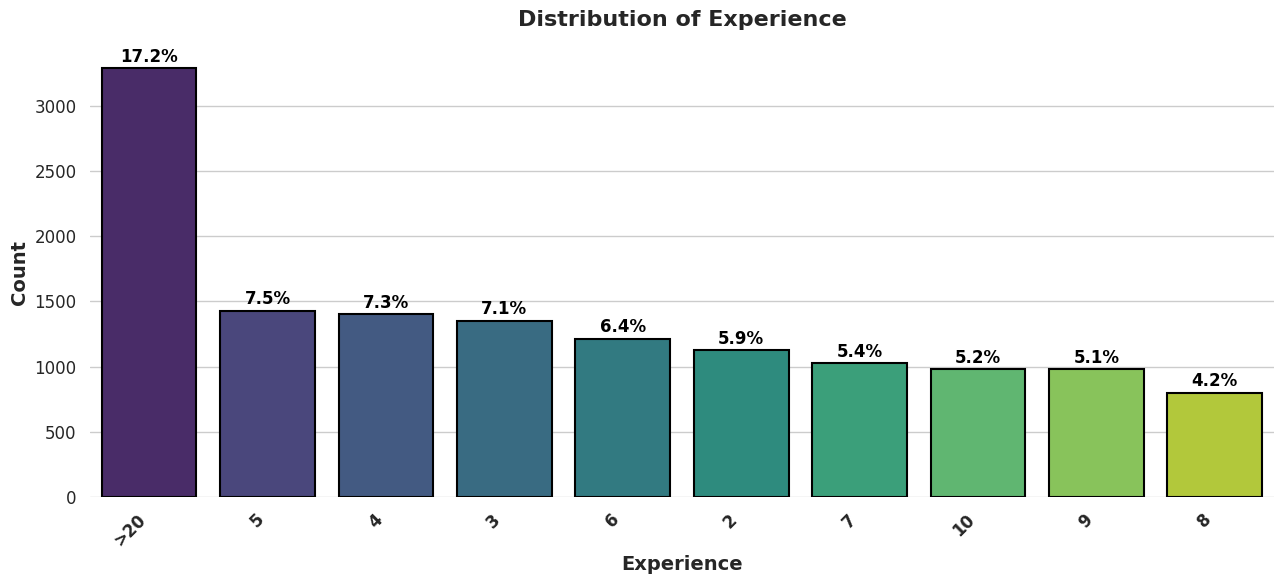

In [ ]:
# 9. Observation of 'Experience'
labeled_barplot(df, 'experience', perc=True, n=10)

- **Highly Experienced Leaders:** The largest single group consists of highly experienced professionals with more than 20 years of experience (">20"), accounting for 17.2% of the top 10 categories.   
- **Mid-Level Professionals:** The next most common experience levels are tightly clustered around the mid-level range, specifically 5 years (7.5%), 4 years (7.3%), and 3 years (7.1%).   
- **Steady Distribution:** For the remaining groups (ranging from 6 years to 8 years of experience), the number of candidates drops very gradually and steadily from 6.4% down to 4.2%.

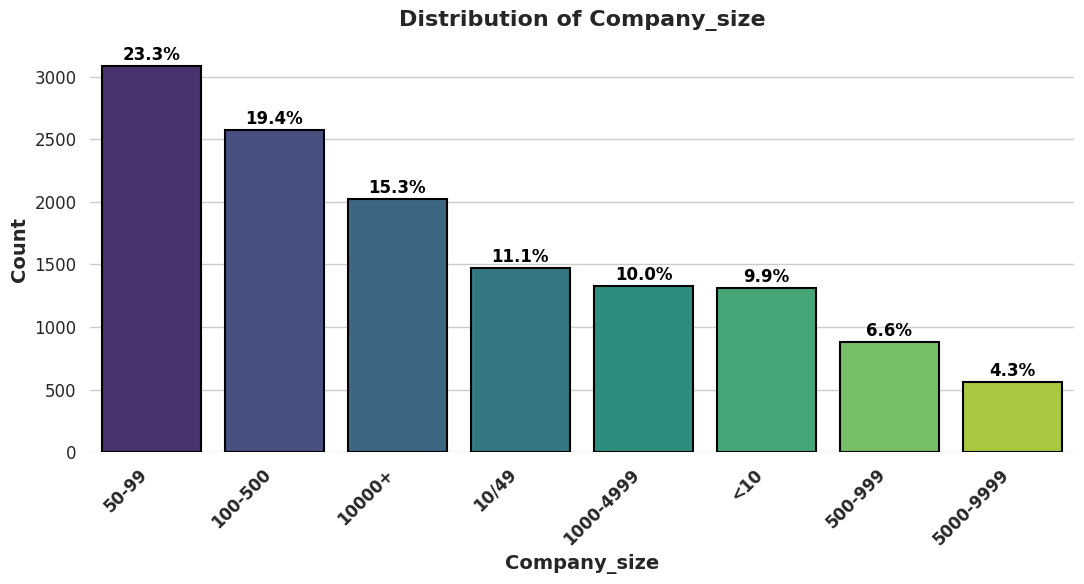

In [ ]:
# 10. Observation of 'Company_size'
labeled_barplot(df, 'company_size', perc=True)

- **Small to Medium Companies Lead:** The most common company sizes are 50-99 employees (23.3%) and 100-500 employees (19.4%).   
- **Massive Corporations:** A significant portion of candidates work for giant enterprises with 10,000+ employees, making it the third-largest group at 15.3%.   
- **Micro and Small Startups:** Companies with fewer than 50 employees (categories "10/49" and "<10") make up a combined total of 21.0% of the dataset.   
- **Least Common:** Very few candidates come from mid-to-large companies with 5,000-9,999 employees (4.3%) or 500-999 employees (6.6%).  

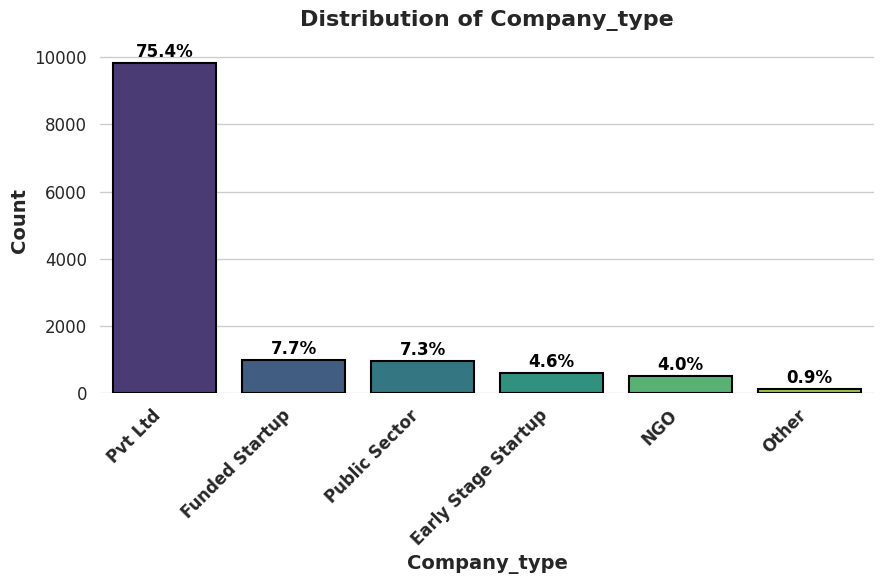

In [ ]:
# 11. Observation of 'Company_type'
labeled_barplot(df, 'company_type', perc=True)

- **Private Sector Dominance:** The vast majority of the candidates work for Private Limited (Pvt Ltd) companies, which make up a massive 75.4% of the dataset.   
- **Startups and Public Sector:** Funded Startups (7.7%) and the Public Sector (7.3%) represent the next largest groups, but they are very small in comparison to the private sector.   
- **Minority Groups:** Early Stage Startups (4.6%) and NGOs (4.0%) employ a much smaller fraction of the candidates.   
- **Rare Category:** Candidates coming from "Other" company types are extremely rare, accounting for just 0.9% of the data.

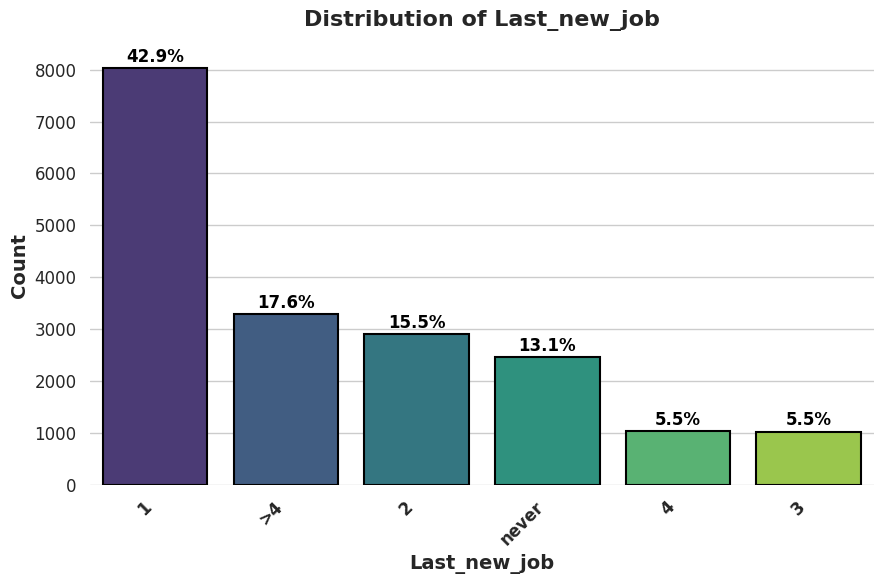

In [ ]:
# 12. Observation of 'Last_new_job'
labeled_barplot(df, 'last_new_job', perc=True)

- **Most Common Gap:** The largest group of candidates changed jobs 1 year ago, representing 42.9% of the dataset.   
- **Long-Term Employees:** The second most common category is people waiting more than 4 years (">4") to switch jobs, accounting for 17.6% of the data.   -
- **First-Time Workers:** About 13.1% of candidates have "never" changed jobs, suggesting they are likely still at their first company.   
- **Least Common Gaps:** Very few people have exactly a 3-year or 4-year gap, with both categories sitting at just 5.5% each.

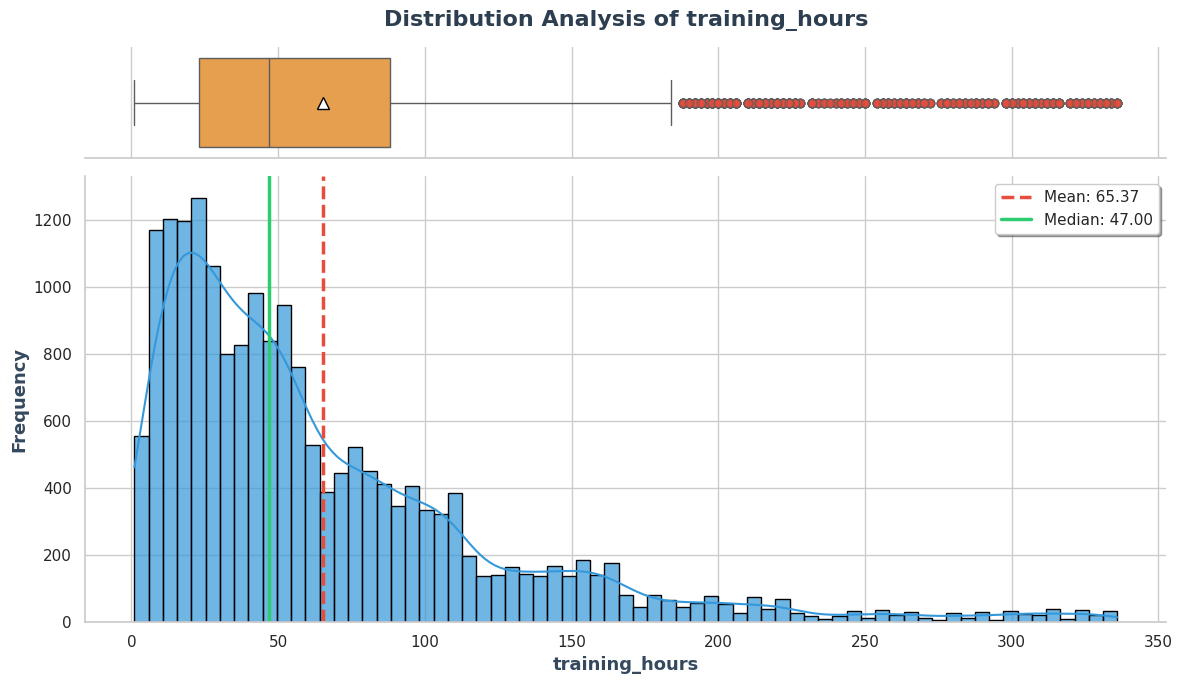

In [ ]:
# 13. Observation of 'Training_hours'
histogram_boxplot(df, 'training_hours')

- **Right-Skewed Shape:** The graph is heavily skewed to the right, meaning it has a tall peak on the left and a long, flat tail stretching out to the right side.   
- **Most Common Range:** The vast majority of candidates complete a relatively low number of training hours, with the data heavily concentrated between roughly 10 and 50 hours.   
- **Averages Pulled Up:** The typical candidate completes 47.00 hours of training (the Median). However, the overall average (Mean) is much higher at 65.37 hours.   
- **Extreme Outliers:** The reason the Mean is so high is visible in the boxplot at the top, which shows a long trail of red dots. These are extreme outliers representing a small group of people who completed an unusually high amount of training, reaching up to 300+ hours.

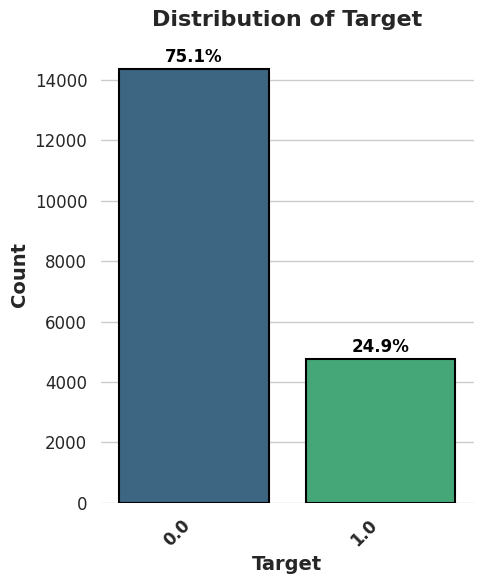

In [ ]:
# 14. Observation of 'Traget'
labeled_barplot(df, 'target', perc=True)

- **Majority Class (0.0):** The vast majority of the data falls into class 0.0, which makes up exactly 75.1% of the dataset.   
- **Minority Class (1.0):** The remaining 24.9% of the candidates belong to class 1.0.   
- **Imbalanced Dataset:** This shows a clear 3-to-1 imbalance in your target variable. This is a crucial detail for your machine learning model, as you may need to use techniques like SMOTE or class weighting later on to prevent the model from becoming biased towards class 0.0.

### Bivariate Analysis

In [ ]:
def distribution_plot_wrt_target(data, predictor, target):
    fig, axs = plt.subplots(2, 2, figsize=(12, 10))

    target_uniq = data[target].unique()

    # 'viridis' palette se 2 vibrant colors nikal rahe hain taaki histograms aur boxplots match karein
    colors = sns.color_palette("viridis", 2)

    # 1. Histogram for Target Class 1
    axs[0, 0].set_title(f"Distribution of {predictor} (Target = {target_uniq[0]})", fontweight='bold', fontsize=12)
    sns.histplot(
        data=data[data[target] == target_uniq[0]],
        x=predictor,
        kde=True,
        ax=axs[0, 0],
        color=colors[0],
        stat="density",
        edgecolor="black"
    )

    # 2. Histogram for Target Class 2
    axs[0, 1].set_title(f"Distribution of {predictor} (Target = {target_uniq[1]})", fontweight='bold', fontsize=12)
    sns.histplot(
        data=data[data[target] == target_uniq[1]],
        x=predictor,
        kde=True,
        ax=axs[0, 1],
        color=colors[1],
        stat="density",
        edgecolor="black"
    )

    # 3. Boxplot with outliers
    axs[1, 0].set_title(f"Boxplot of {predictor} w.r.t Target", fontweight='bold', fontsize=12)
    sns.boxplot(
        data=data,
        x=target,
        y=predictor,
        ax=axs[1, 0],
        palette="viridis",
        hue=target,
        legend=False
    )

    # 4. Boxplot without outliers
    axs[1, 1].set_title(f"Boxplot without outliers w.r.t Target", fontweight='bold', fontsize=12)
    sns.boxplot(
        data=data,
        x=target,
        y=predictor,
        ax=axs[1, 1],
        showfliers=False,
        palette="viridis",
        hue=target,
        legend=False
    )

    plt.tight_layout()
    plt.show()

In [ ]:
def stacked_barplot(data, predictor, target):
    """
    Print the category counts and plot a stacked bar chart

    data: dataframe
    predictor: independent variable
    target: target variable
    """
    count = data[predictor].nunique()
    sorter = data[target].value_counts().index[-1]

    # 1. Table Print karna
    tab1 = pd.crosstab(data[predictor], data[target], margins=True).sort_values(
        by=sorter, ascending=False
    )
    print(tab1)
    print("-" * 120)

    # 2. Normalized data for Stacked Plot
    tab = pd.crosstab(data[predictor], data[target], normalize="index").sort_values(
        by=sorter, ascending=False
    )

    # 3. Plotting
    ax = tab.plot(
        kind="bar",
        stacked=True,
        figsize=(count + 5, 6),
        colormap="viridis",
        edgecolor="black",
        linewidth=1.2
    )

    # 4. Graph Aesthetics (Titles and Labels)
    plt.title(f"Stacked Proportion of {target} by {predictor}", fontsize=14, fontweight="bold")
    plt.xlabel(predictor, fontsize=12, fontweight="bold")
    plt.ylabel("Proportion", fontsize=12, fontweight="bold")
    plt.xticks(rotation=45, ha='right', fontweight='bold') # Labels overlapping rokne ke liye

    # 5. Set legends properly
    plt.legend(
        title=target,
        title_fontproperties={'weight': 'bold'},
        loc="upper left",
        bbox_to_anchor=(1.02, 1),
        frameon=False
    )

    plt.tight_layout()
    plt.show()

target      0.0   1.0    All
city                        
All       14381  4777  19158
city_21    1105  1597   2702
city_103   3427   928   4355
city_160    646   199    845
city_16    1354   179   1533
...         ...   ...    ...
city_2        7     0      7
city_39      11     0     11
city_62       5     0      5
city_8        4     0      4
city_82       4     0      4

[124 rows x 3 columns]
------------------------------------------------------------------------------------------------------------------------




In [ ]:
# 1. Observation of "City" vs "Target"
stacked_barplot(df, "city", "target")

- **City Matters:** The proportion of candidates looking for a job change (the yellow section) varies drastically across different cities.   
- **High Job Seekers (Left Side):** Cities positioned on the far left of the chart have an extremely high rate of people wanting to leave their jobs, with some cities being almost entirely yellow.   
- **High Retention (Right Side):** Cities on the far right have almost no one looking for a job change, shown by the solid dark purple bars (target 0.0).   


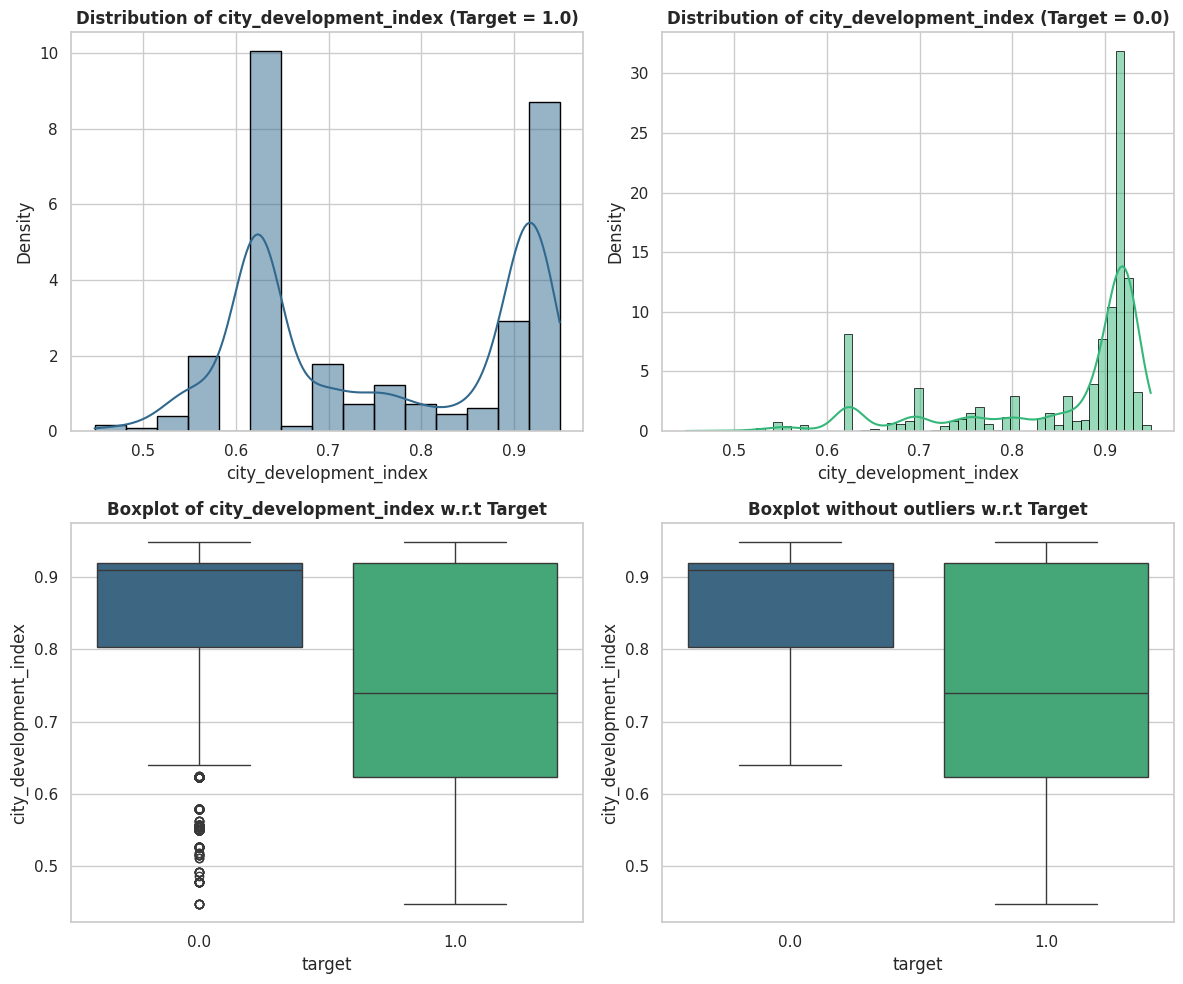

In [ ]:
# 2. Observation of "City_development_index" vs "Target"
distribution_plot_wrt_target(df, "city_development_index", "target")

- **Non-Seekers (Target 0.0):** Candidates who do not want a job change are heavily concentrated in highly developed cities, with a massive single peak just above the 0.90 mark.   
- **Job Seekers (Target 1.0):** Candidates actively looking for a job change come from a wider variety of cities, showing a distinct double-peak: one group in highly developed cities (~ 0.90) and another major group in mid-developed cities (~ 0.62).   
- **Median Difference:** The boxplots at the bottom confirm that the median city development index is significantly lower for people wanting to switch jobs compared to those who want to stay.   
- **Model Importance:** Because there is such a clear difference in behavior between the two groups based on their city's development score, this feature will be highly valuable for your machine learning model.

target    0.0   1.0    All
gender                    
All     11262  3388  14650
Male    10209  3012  13221
Female    912   326   1238
Other     141    50    191
------------------------------------------------------------------------------------------------------------------------


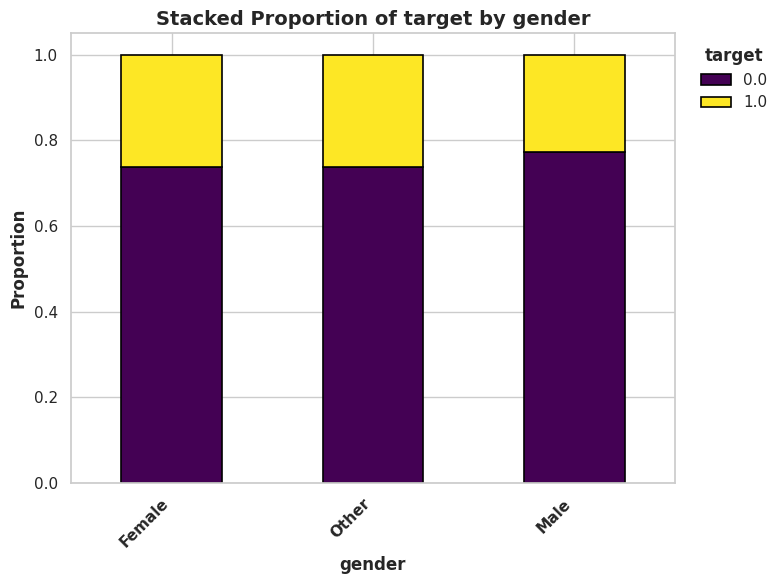

In [ ]:
# 3. Observation of "Gender" vs "Target"
stacked_barplot(df, "gender", "target")

- **Similar Proportions:** The yellow section (candidates looking for a job change) is almost the same size across all three gender categories.   
- **Slight Difference in Males:** Males have a very slightly lower proportion of job seekers compared to Females and the "Other" category, but the difference is minimal.   
- **Not a Strong Predictor:** Because the job-seeking behavior is so consistent regardless of gender, this specific column might not be a very strong feature for your machine learning model to predict the target.

target                     0.0   1.0    All
relevent_experience                        
All                      14381  4777  19158
Has relevent experience  10831  2961  13792
No relevent experience    3550  1816   5366
------------------------------------------------------------------------------------------------------------------------


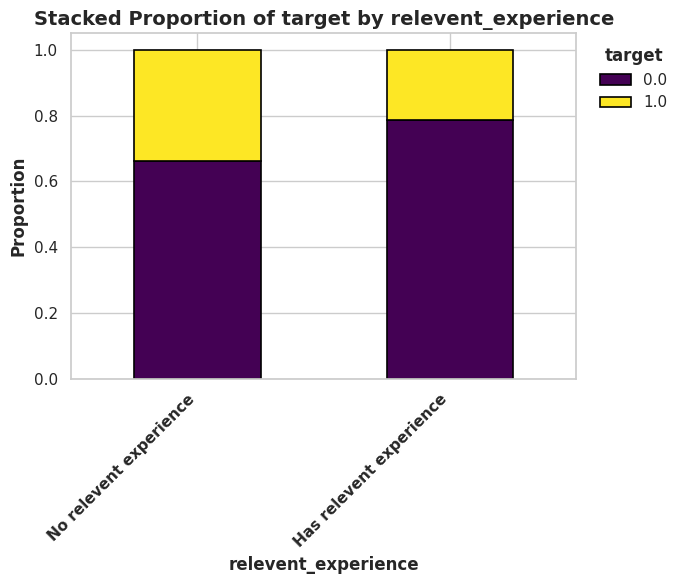

In [ ]:
# 4. Observation of "Relevent_experience" vs "Target"
stacked_barplot(df, "relevent_experience", "target")

- **Higher Job Seeking:** Candidates with "No relevent experience" have a visibly larger yellow section, meaning they are more likely to be looking for a job change.   
- **More Stable:** Candidates who "Has relevent experience" have a larger dark purple section, showing they are more likely to stay in their current roles and not seek a change.   
- **Key Takeaway:** A lack of relevant experience is a solid indicator that a candidate might want to switch jobs, making this a useful feature for your model.

target                 0.0   1.0    All
enrolled_university                    
All                  14118  4654  18772
no_enrollment        10896  2921  13817
Full time course      2326  1431   3757
Part time course       896   302   1198
------------------------------------------------------------------------------------------------------------------------


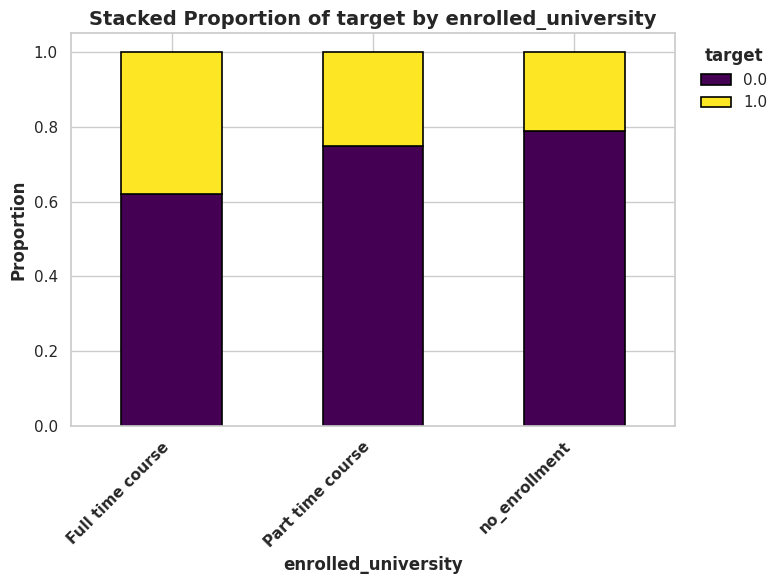

In [ ]:
# 5. Observation of "Enrolled_university" vs "Target"
stacked_barplot(df, "enrolled_university", "target")

- **Full-Time Students Most Likely to Switch:** Candidates enrolled in a "Full time course" have the largest yellow section, meaning they are the most likely group to be looking for a job change.   
- **Not Enrolled are Most Stable:** Candidates with "no_enrollment" have the largest dark purple section, indicating they are the least likely to seek a new job and prefer to stay in their current roles.   
- **Part-Time in the Middle:** People taking a "Part time course" fall right in the middle between full-time students and non-enrolled individuals in terms of wanting a job change.   
- **Key Takeaway:** Active university enrollment, especially a full-time course, strongly increases the chances that a candidate is looking for a new job opportunity.

target             0.0   1.0    All
education_level                    
All              14025  4673  18698
Graduate          8353  3245  11598
Masters           3426   935   4361
High School       1623   394   2017
Phd                356    58    414
Primary School     267    41    308
------------------------------------------------------------------------------------------------------------------------


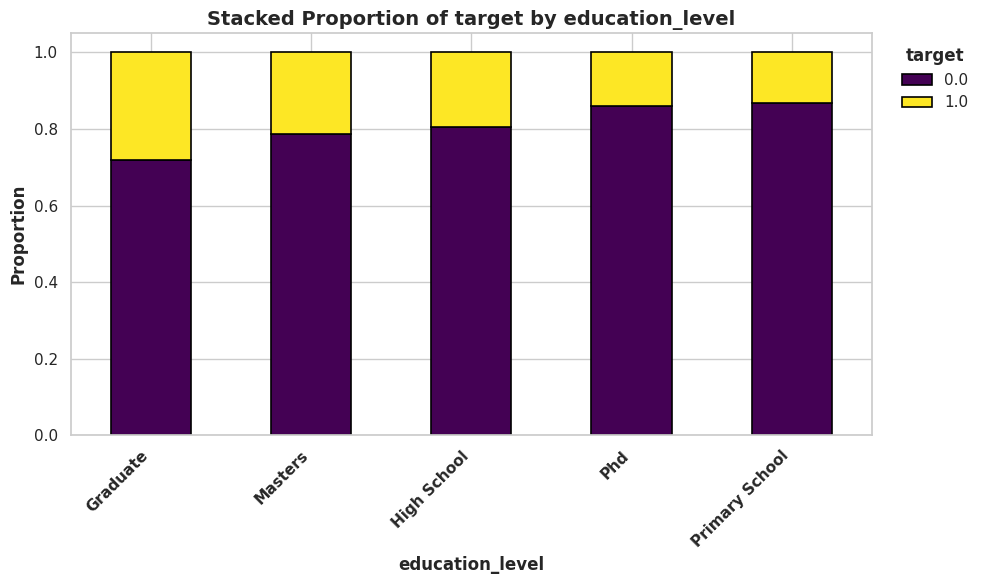

In [ ]:
# 6. Observation of "Education_level" vs "Target"
stacked_barplot(df, "education_level", "target")

- **Graduates Most Active:** Candidates with a "Graduate" education level have the largest yellow section, making them the most likely group to seek a job change.   
- **Most Stable Groups:** Individuals with a "Phd" or a "Primary School" education have the largest dark purple sections, meaning they are the least likely to switch jobs.   
- **Middle Ground:** Candidates with a "Masters" degree or a "High School" education show a moderate, very similar interest in changing jobs.   
- **Key Takeaway:** Graduates are the most active job seekers, while those at the absolute highest (Phd) and lowest (Primary School) educational extremes strongly prefer to stay in their current roles.

target              0.0   1.0    All
major_discipline                    
All               12117  4228  16345
STEM              10701  3791  14492
Humanities          528   141    669
Other               279   102    381
Business Degree     241    86    327
No Major            168    55    223
Arts                200    53    253
------------------------------------------------------------------------------------------------------------------------


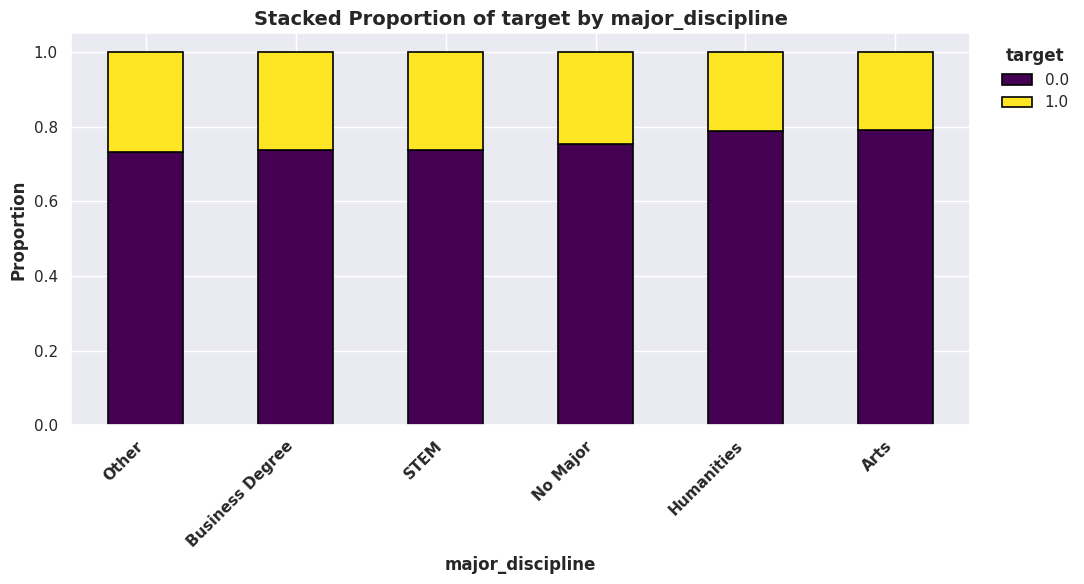

In [ ]:
# 7. Observation of "Major_discipline" vs "Target"
stacked_barplot(df, "major_discipline", "target")

- **Consistent Behavior:** The proportion of candidates looking for a job change (the yellow section) is quite similar across all educational majors.   
- **Slightly Higher Seekers:** Candidates with "Other", "Business Degree", and "STEM" backgrounds show a slightly higher tendency to seek a job change.   
- **Most Stable:** "Arts" and "Humanities" majors have the largest dark purple sections, indicating they are the least likely to look for new opportunities.   
- **Key Takeaway:** Because the job-seeking behavior is so evenly spread, a candidate's major discipline might not be a strong predictor for your machine learning model.  

target        0.0   1.0    All
experience                    
All         14339  4754  19093
>20          2783   503   3286
3             876   478   1354
4             946   457   1403
5            1018   412   1430
2             753   374   1127
6             873   343   1216
7             725   303   1028
<1            285   237    522
1             316   233    549
9             767   213    980
10            778   207    985
8             607   195    802
11            513   151    664
15            572   114    686
14            479   107    586
12            402    92    494
13            322    77    399
16            436    72    508
17            285    57    342
19            251    53    304
18            237    43    280
20            115    33    148
------------------------------------------------------------------------------------------------------------------------


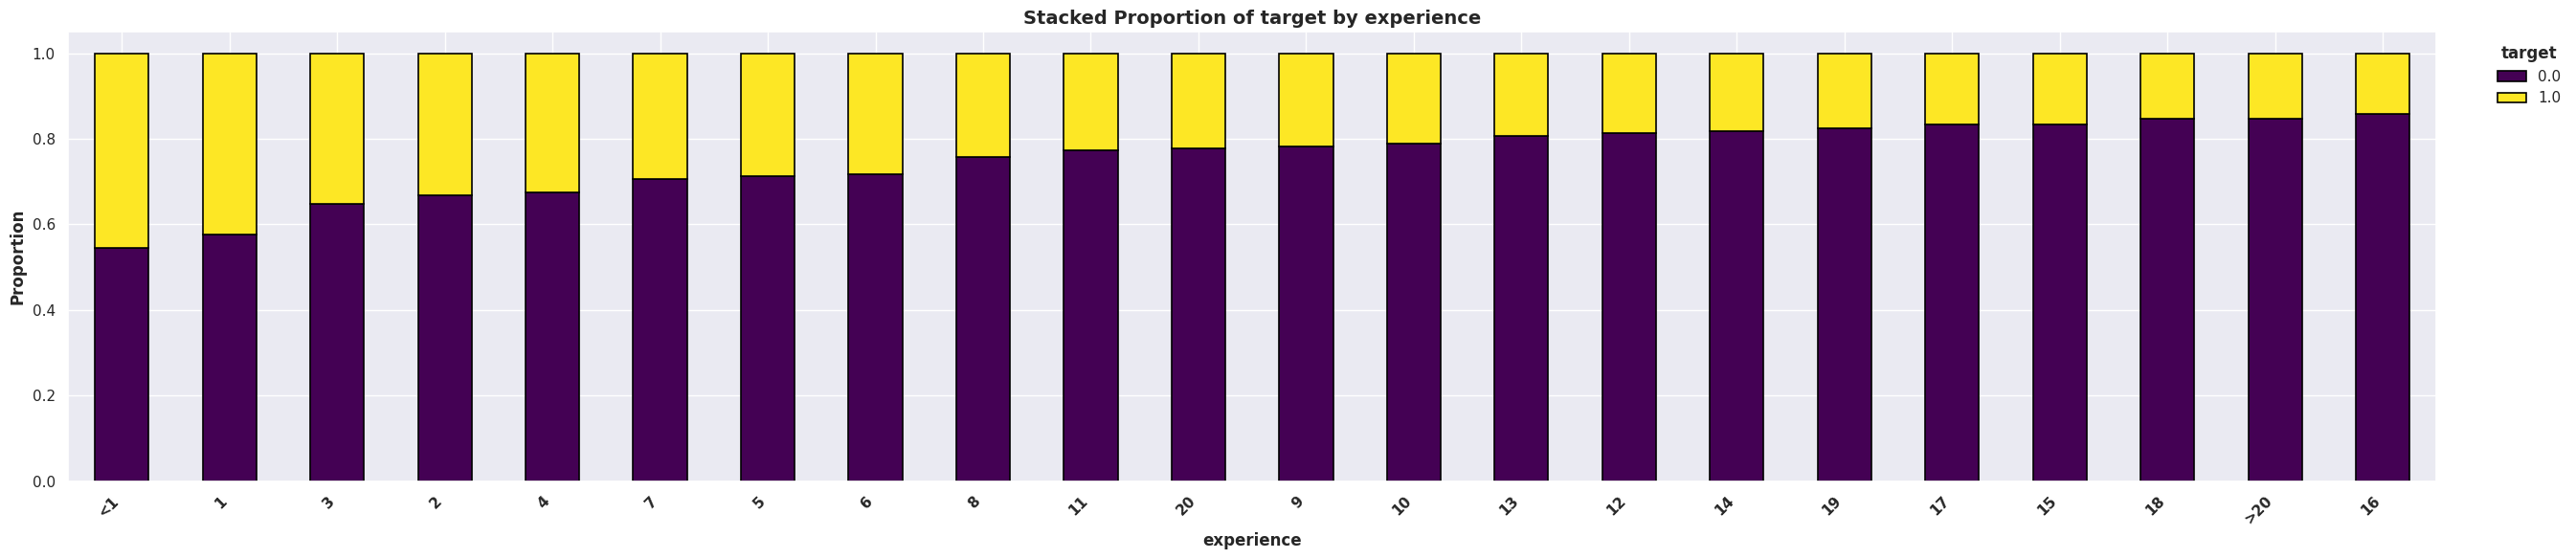

In [ ]:
# 8. Observation of "Experience" vs "Target"
stacked_barplot(df, "experience", "target")

- **Beginners Seek Change:** Candidates with very low experience, especially those with <1 year and 1 year, have the largest yellow sections, making them the most likely to look for a new job.   
- **Experience Brings Stability:** As you move from left to right on the chart, the dark purple section steadily grows, showing that as people gain more years of experience, they become less likely to switch jobs.   
- **Veterans Stay Put:** Highly experienced professionals (like those with 16, >20, 18, and 15 years) have the smallest yellow bars, meaning they are highly stable in their current roles.   
- **Key Takeaway:** There is a very clear and steady trend: less experience equals higher chances of job hunting. This makes "experience" a very strong and important feature for your machine learning model.

target          0.0   1.0    All
company_size                    
All           10853  2367  13220
50-99          2538   545   3083
100-500        2156   415   2571
10000+         1634   385   2019
10/49          1127   344   1471
<10            1084   224   1308
1000-4999      1128   200   1328
500-999         725   152    877
5000-9999       461   102    563
------------------------------------------------------------------------------------------------------------------------


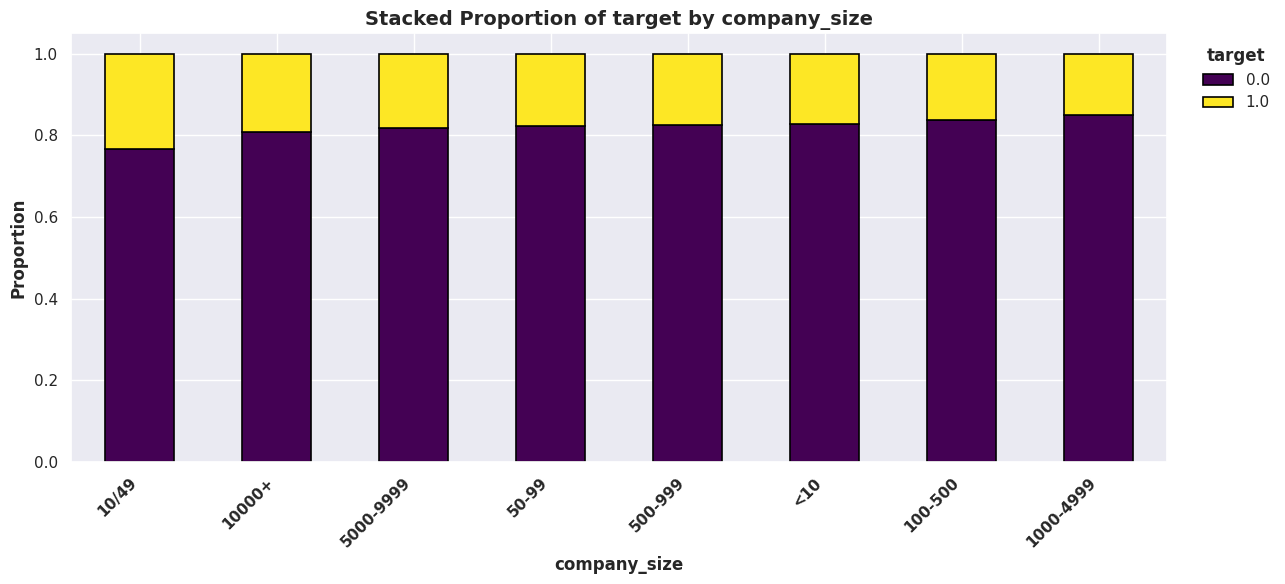

In [ ]:
# 9. Observation of "Company_size" vs "Target"
stacked_barplot(df, "company_size", "target")

- **Small Companies See More Movement:** Candidates working in small companies with "10/49" employees have the largest yellow section, making them slightly more likely to seek a job change compared to the rest.   
- **Most Stable Group:** Employees in mid-to-large companies sized "1000-4999" have the largest dark purple section, indicating they are the least likely to leave their current roles.   
- **Consistent Behavior:** For almost all other company sizes (from <10 up to massive 10000+ enterprises), the proportion of people looking for a new job is remarkably similar.   
- **Key Takeaway:** While being in a 10-49 person company slightly increases the chances of job hunting, company_size overall does not show drastic differences across the other categories.

target                 0.0   1.0    All
company_type                           
All                  10625  2393  13018
Pvt Ltd               8042  1775   9817
Public Sector          745   210    955
Early Stage Startup    461   142    603
Funded Startup         861   140   1001
NGO                    424    97    521
Other                   92    29    121
------------------------------------------------------------------------------------------------------------------------


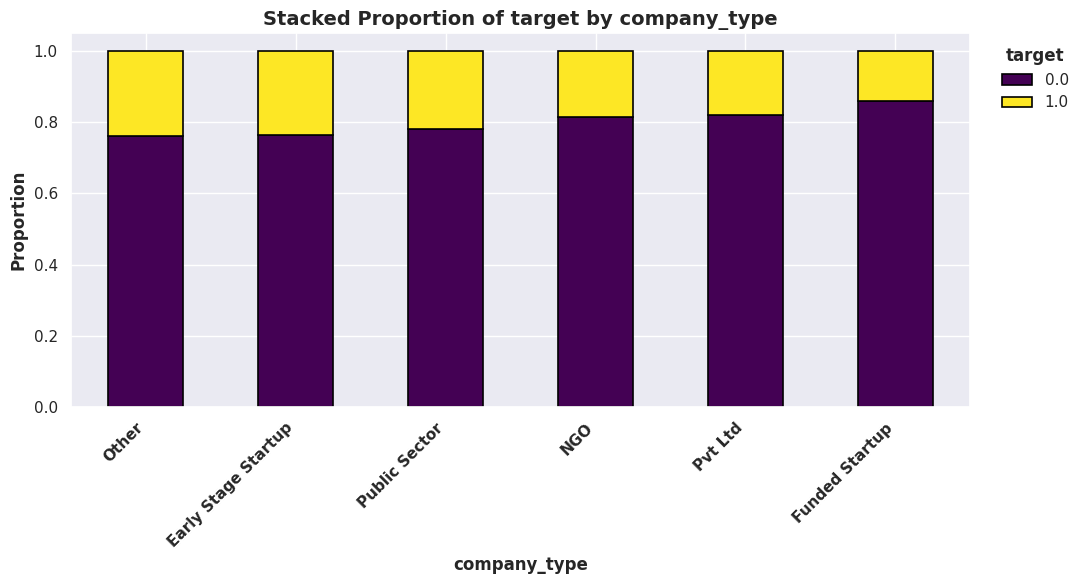

In [ ]:
# 10. Observation "Company_type" vs "Target"
stacked_barplot(df, "company_type", "target")

- **Highest Movers:** Candidates working in "Other" company types and "Early Stage Startups" have the largest yellow sections, making them the most likely to look for a job change.   
- **Most Stable:** Employees at "Funded Startups" have the largest dark purple bar, indicating they are the most stable and least likely to leave their current roles.   
- **Consistent Middle:** "NGOs" and "Pvt Ltd" companies show almost identical, relatively low rates of job seekers.   
- **Key Takeaway:** While the differences are not massive, working at an early-stage startup slightly increases the chance of a candidate hunting for a new job compared to working at a more secure funded startup.

target          0.0   1.0    All
last_new_job                    
All           14112  4623  18735
1              5915  2125   8040
never          1713   739   2452
2              2200   700   2900
>4             2690   600   3290
3               793   231   1024
4               801   228   1029
------------------------------------------------------------------------------------------------------------------------


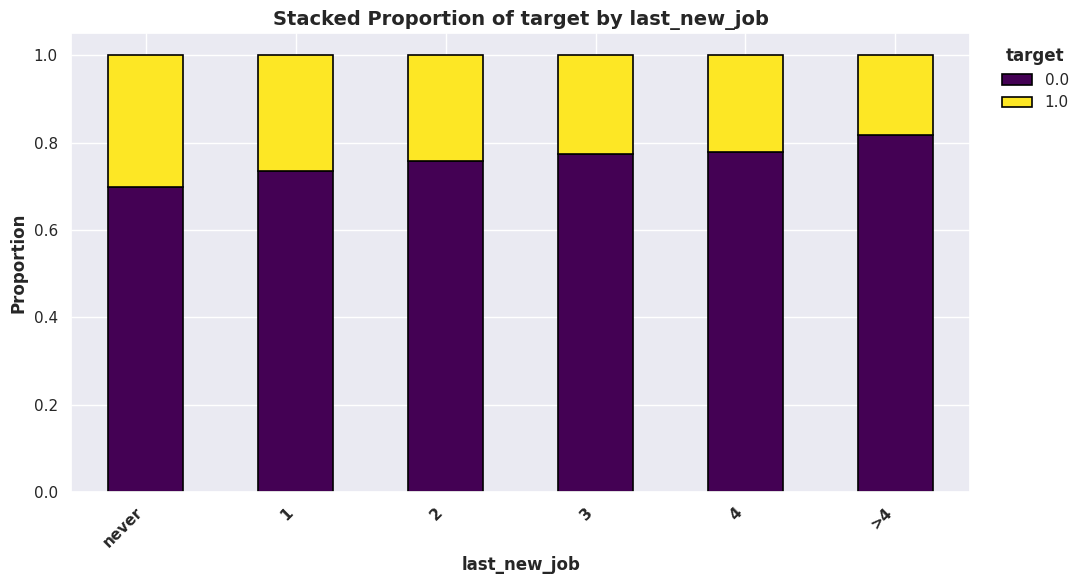

In [ ]:
# 11. Observation of "Last_new_job" vs "Target"
stacked_barplot(df, "last_new_job", "target")

- **First-Time Seekers:** Candidates who have "never" changed jobs have the largest yellow section, making them the most likely group to be looking for a job change.   
- **Steady Decline:** As the time since a candidate's last new job increases from 1 year to 4 years, the yellow section steadily shrinks, showing they become less interested in switching jobs.   
- **Most Stable Employees:** People who haven't changed jobs in over 4 years (">4") have the largest dark purple bar, meaning they are the most settled and least likely to leave their current role.   
- **Key Takeaway:** The longer someone goes without changing jobs, the less likely they are to start hunting for a new one, showing a very clear trend for your model.  

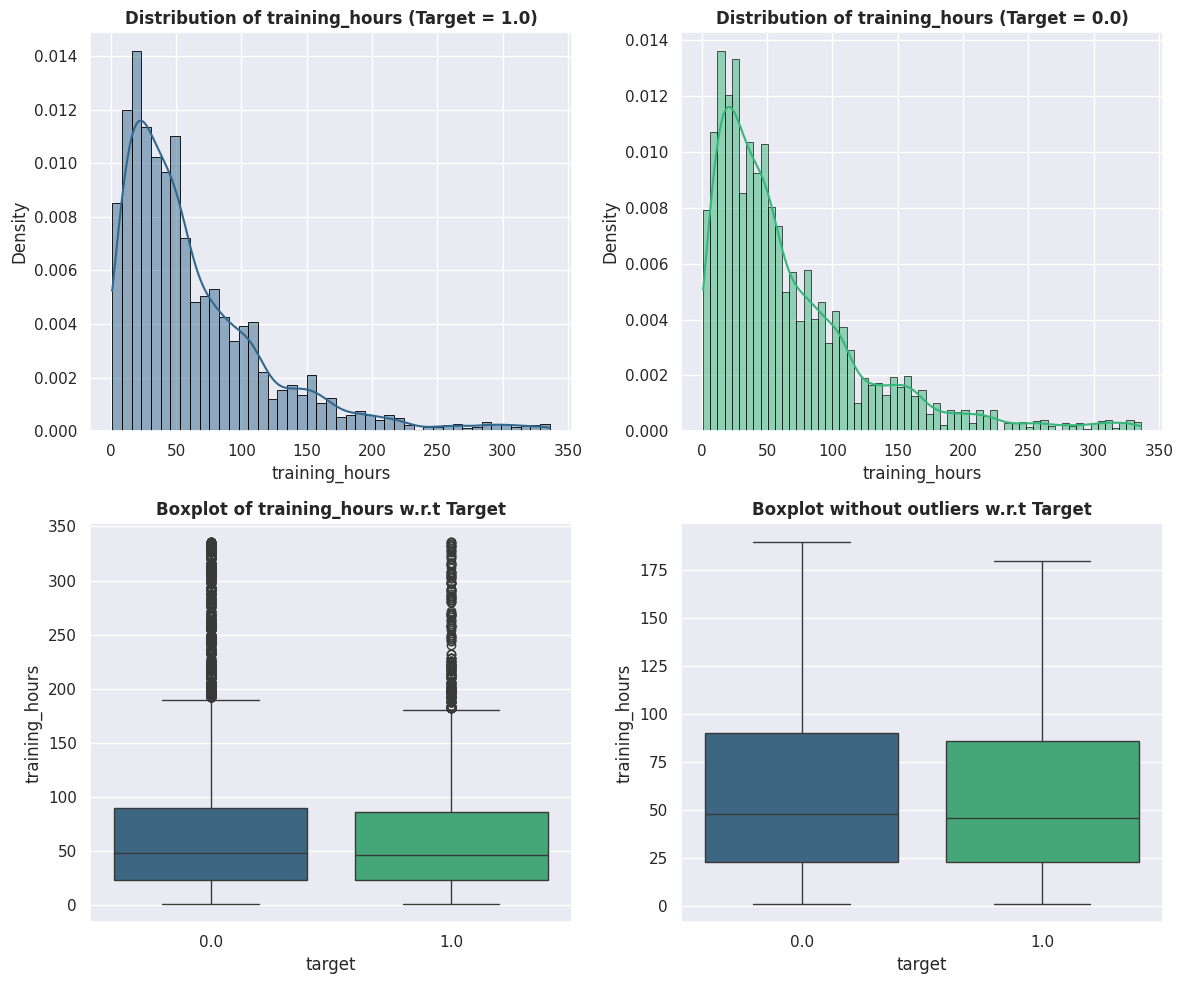

In [ ]:
# 12. Observation of "Training_hours" vs "Target"
distribution_plot_wrt_target(df, "training_hours", "target")

- **Identical Distributions:** The shape of the histogram is almost exactly the same for both candidates looking for a job change (Target 1.0) and those who are not (Target 0.0).   
- **Mostly Low Hours:** For both groups, the vast majority of people complete around 20 to 50 hours of training, showing a heavy right skew with many outliers.   
- **Equal Medians:** The boxplots confirm that the median training hours and the overall spread of the data are practically identical for both target classes.   
- **Key Takeaway:** Because the amount of training hours does not show any clear difference between the two groups, this feature will likely be very weak and not help your machine learning model make predictions.

### Multivariate Analysis

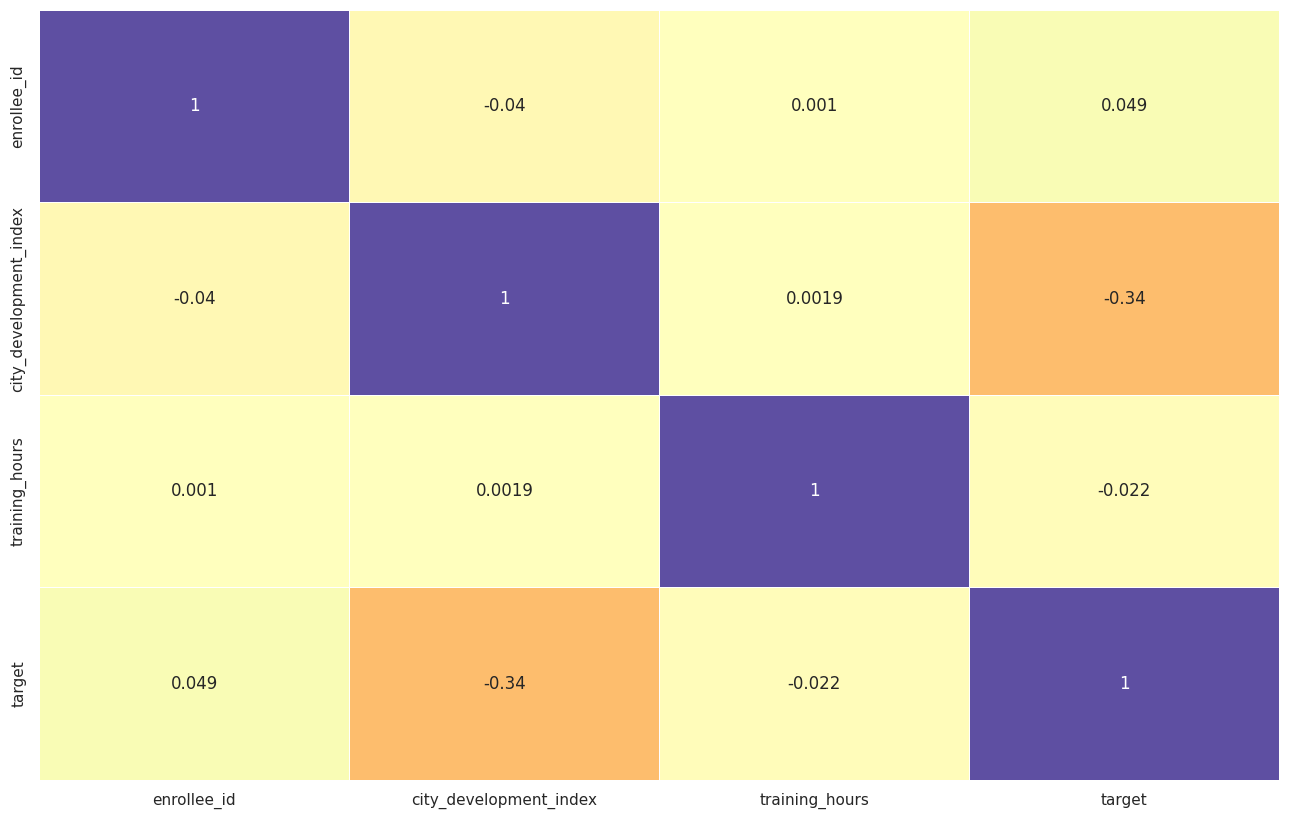

In [ ]:
sns.set(rc={'figure.figsize':(16,10)})
sns.heatmap(df.corr(numeric_only=True),
            annot=True,
            linewidths=.5,
            center=0,
            cbar=False,
            cmap="Spectral")
plt.show()

- **Strongest Link:** The only notable relationship in the dataset is a negative correlation of -0.34 between city_development_index and the target. This suggests that as a city's development index goes up, the target value tends to go down (meaning candidates from highly developed cities might be less likely to look for a job change).   
- **Training Doesn't Matter:** The training_hours column has virtually zero correlation (-0.022) with the target. This means the amount of time someone spends training has no direct linear impact on the final outcome.   
- **Irrelevant ID:** The enrollee_id shows almost zero correlation (0.049 and -0.04) with other variables. This confirms your earlier observation that it is just a random number and has no predictive value.   
- **Overall Weak Relationships:** Aside from the city development index, all other numerical variables are very weakly connected to each other, with correlation scores sitting very close to zero.

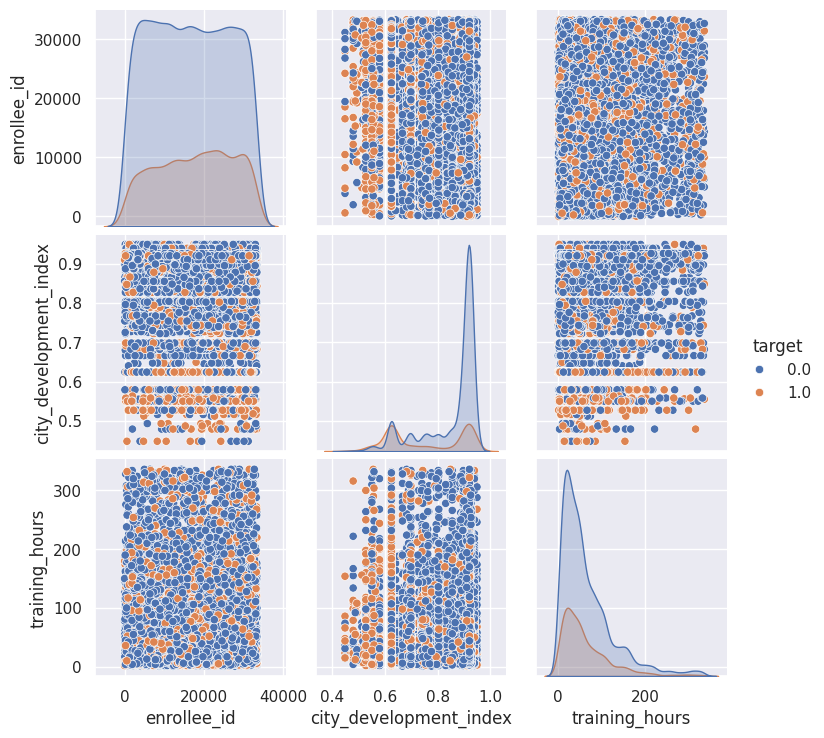

In [ ]:
sns.pairplot(df, hue='target')
plt.show()

- **City Development is Key:** The distribution for city_development_index shows the biggest difference between the two groups. Candidates not looking for a job change (blue/class 0.0) mostly come from highly developed cities near the 0.9 mark, while those wanting a job change (orange/class 1.0) have a distinct peak in mid-developed cities around the 0.6 mark.   
- **Training Hours Don't Separate:** The distribution curve for training_hours is almost identical for both the blue and orange groups. This means the amount of training someone completes does not help predict whether they want to change jobs.   
- **No Clear Relationships:** The scatter plots (the boxes filled with dots) show massive, randomly overlapping clouds without any clear diagonal lines or clusters. This confirms there is no strong linear relationship between these numeric variables.   
- **Drop the ID:** As seen in previous graphs, enrollee_id forms a completely random, flat block of dots across all comparisons, confirming once again that it has absolutely no predictive value for your machine learning model.